# Installs/Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## Setup

In [16]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.size': 9,
    'axes.linewidth': 0.5,
    'lines.linewidth': 1.0,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
})


fontsize = 9
markers = ['o', 'x', '^', 'D', 'v', 'P']
markersize = 6

# H2 PES

In [3]:
fci_values = np.array([[-0.3122699 ,  1.25008782,  1.56864099,  3.18485267],
       [-1.05515979, -0.07074011,  0.26700034,  1.30148575],
       [-1.13711707, -0.5427821 , -0.17923903,  0.45980452],
       [-1.10115033, -0.74587179, -0.35229063,  0.03904763],
       [-1.04578314, -0.8427812 , -0.41657639, -0.18775207],
       [-0.99814935, -0.89058478, -0.43151291, -0.3071925 ],
       [-0.96633454, -0.91369215, -0.4235421 , -0.36080045],
       [-0.94864111, -0.92453732, -0.40626037, -0.37643216],
       [-0.93998171, -0.92946888, -0.38644559, -0.37288701],
       [-0.93567632, -0.93184547, -0.36429585, -0.35912511],
       [-0.93404795, -0.93272023, -0.34468368, -0.34282443],
       [-0.93345918, -0.93302392, -0.32789967, -0.32727446],
       [-0.93325346, -0.93312416, -0.3132147 , -0.31302652],
       [-0.9331906 , -0.93315273, -0.30117347, -0.30111843],
       [-0.93317136, -0.93316083, -0.29084711, -0.29083203]])

vqd_values = np.array([[-0.31226995,  1.25008715,  1.56864111,  3.18485271],
       [-1.05515984, -0.07074071,  0.26700044,  1.3014858 ],
       [-1.13711712, -0.54278261, -0.17923895,  0.45980457],
       [-1.10115038, -0.74587224, -0.35229056,  0.03904768],
       [-1.04578319, -0.84278158, -0.41657634, -0.18775202],
       [-0.9981494 , -0.89058511, -0.43151286, -0.30719246],
       [-0.96633458, -0.91369243, -0.42354207, -0.36080041],
       [-0.94864114, -0.92453757, -0.40626033, -0.37643214],
       [-0.93998172, -0.9294691 , -0.38644556, -0.372887  ],
       [-0.93566163, -0.93185366, -0.36417511, -0.35903378],
       [-0.93403714, -0.93272608, -0.34447489, -0.3426381 ],
       [-0.9334535 , -0.9330269 , -0.32763378, -0.32702061],
       [-0.93325468, -0.93312372, -0.31336455, -0.31317379],
       [-0.93319078, -0.93315277, -0.3012374 , -0.30118199],
       [-0.93317136, -0.93316093, -0.29084709, -0.29083204]])



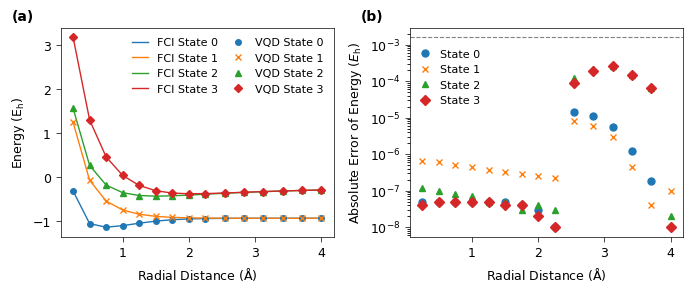

In [4]:

distances_plotting = np.concatenate((np.linspace(0.25, 2.0, 8),
                                     np.linspace(2.25, 4.0, 7)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.0))

# --- Panel (a): PES ---
for i in range(4):
    ax1.plot(distances_plotting, fci_values[:, i],
             label=f'FCI State {i}', linestyle='-', color=f'C{i}')
for i in range(4):
    ax1.plot(distances_plotting, vqd_values[:, i],
             label=f'VQD State {i}', marker=markers[i],
             linestyle='', markersize=4, color=f'C{i}')

ax1.set_xlabel(r'Radial Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax1.set_ylabel(r'Energy ($\text{E}_\text{h}$)', fontsize=fontsize)
ax1.tick_params(axis='both', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, ncol=2, frameon=False,
           handlelength=1.5, columnspacing=1.0)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Error ---
error = np.abs(vqd_values - fci_values)
colors = [f'C{i}' for i in range(4)]

for i in range(fci_values.shape[1]):
    ax2.plot(distances_plotting, error[:, i], marker=markers[i],
             markersize=5, linestyle='', color=colors[i],
             label=f'State {i}')

ax2.axhline(y=1.6e-3, color='grey', linestyle='--', linewidth=0.8)
ax2.set_yscale('log')
ax2.set_xlabel(r'Radial Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax2.set_ylabel(r'Absolute Error of Energy ($E_\text{h}$)', fontsize=fontsize)
ax2.tick_params(axis='both', labelsize=fontsize)
ax2.legend(fontsize=fontsize - 1, frameon=False, handlelength=1.0, loc='upper left', bbox_to_anchor=(0.0, .945))
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
# fig.savefig('Plots/H2_PES_and_Error.png', dpi=900, bbox_inches='tight')
plt.show()

# CO2/H2S

## Imports

In [38]:
from third_party.vibrational_dynamics.util_hamil import hamil

In [39]:
from openfermion.linalg import boson_operator_sparse

## Main code

In [40]:
name = 'H2S' # 'H2S' or 'CO2'
trunc = 4

In [41]:
from pathlib import Path

if name == 'H2S':
    p = Path("..") / "data" / "H2S.hdf5"
elif name == 'CO2':
    p = Path("..") / "data" / "CO2.hdf5"

In [42]:
if p.exists():
    H = hamil(name)
    H_original_sparse = boson_operator_sparse(H, trunc=trunc)
    H_original_eigenenergies = np.linalg.eigvalsh(H_original_sparse.todense())
    expected = H_original_eigenenergies
    expected = [float(expect.real) for expect in expected]
else:
    print(f"Vibrational Hamiltonian file not found at  {p}. Please reach out to authors of J. Phys. Chem. Lett. 2025, 16, 8, 1855–1864 for access to the data.")
    print("Using expected values calculated previously and stored in this notebook.")
    expected = [3301.7342427201543,
                4563.3857926653845,
                5807.264487336513,
                5840.035817222959,
                5899.923979291553,
                7032.624336737385,
                7066.99422241701,
                7155.429484742616,
                8289.981668765864,
                8349.489174080698,
                8376.01107184572,
                8411.852869361162,
                8579.274441479694,
                9498.71134167291,
                9554.017651153665,
                9574.34937282963,
                9617.214003382043,
                9800.656989341258,
                10762.500800970274,
                10823.79566077401,
                10953.638505816261,
                10982.236492137807,
                11194.926798902803,
                11275.160319409426,
                11942.404226294351,
                12020.181887375918,
                12136.423793949865,
                12171.935725896969,
                12378.383829287859,
                12426.3898876129,
                12486.498126850844,
                13322.957019980284,
                13533.744631330215,
                13555.688649778747,
                13587.65782625127,
                13874.067972137518,
                14507.680153160169,
                14538.933721848927,
                14636.073501604107,
                14730.66615654852,
                14733.97444891031,
                15026.936479874728,
                15645.688195561166,
                15725.985780770017,
                16173.980016704354,
                16187.250499949292,
                16786.415677970355,
                17150.313193064314,
                17343.950680642138,
                17784.827585018214,
                17908.44805975158,
                18232.438579785437,
                18836.475771117464,
                19273.171854407865,
                19949.888876112716,
                20986.367888454086,
                21035.51075347477,
                21862.016957614895,
                22927.068470634662,
                23915.497952608093,
                25596.699775182755,
                26397.18883803244,
                27465.53990323823,
                28420.65202898499]

Vibrational Hamiltonian file not found at  ../data/H2S.hdf5. Please reach out to authors of J. Phys. Chem. Lett. 2025, 16, 8, 1855–1864 for access to the data.
Using expected values calculated previously and stored in this notebook.


In [43]:
if name == 'H2S':
  H2S_VQD_Energies = [np.float64(3301.734323178507), np.float64(4563.385904767243), np.float64(5807.2645136495), np.float64(5840.035908675143), np.float64(5899.937131541012)] # Data stored in "C:\Users\marlo_2lbtn5r\OneDrive\School\Dong Lab\Beckman Project\Code\Bosonic VQE\Data from VQE Runs\Vibrational VQD\H2S_first_5_2\text output.txt"
  H2S_VQD_Energies = [float(energy) for energy in H2S_VQD_Energies]
  en = H2S_VQD_Energies
elif name == 'CO2':
  en = [
  2535.2439214559486,
  3189.544660844184,
  3189.5446624782257,
  3829.124267040216,
  3847.1697717301276,
  # 10080.134167570053,
  3869.374810850096,
  # 3954.5827281282295
  ] # data from "C:\Users\marlo_2lbtn5r\OneDrive\School\Dong Lab\Beckman Project\Code\Vibrational VQD Data\CO2_success_7_states_2\energies.json"

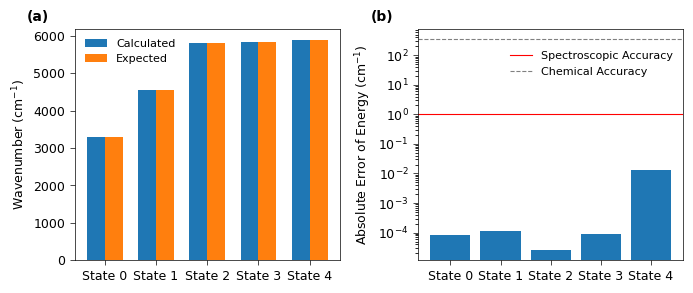

In [44]:
if name == 'H2S':
    max_idx = 5
elif name == 'CO2':
    max_idx = 5

en_subset = en[:max_idx]
expected_subset = expected[:max_idx]
errors = [abs(en_subset[i] - expected_subset[i]) for i in range(max_idx)]

labels = [f'State {i}' for i in range(max_idx)]
x = np.arange(max_idx)
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.0))

# --- Panel (a): Energies ---
ax1.bar(x - width/2, en_subset, width, label='Calculated')
ax1.bar(x + width/2, expected_subset, width, label='Expected')

ax1.set_ylabel(r'Wavenumber (cm$^{-1}$)', fontsize=fontsize)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=fontsize)
ax1.tick_params(axis='y', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, frameon=False)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Errors ---
ax2.bar(x, errors)
ax2.set_yscale('log')
ax2.set_ylabel(r'Absolute Error of Energy (cm$^{-1}$)', fontsize=fontsize)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=fontsize)
ax2.tick_params(axis='y', labelsize=fontsize)

ax2.axhline(y=1, color='r', linestyle='-', linewidth=0.8,
            label='Spectroscopic Accuracy')
ax2.axhline(y=350, color='grey', linestyle='--', linewidth=0.8,
            label='Chemical Accuracy')
ax2.legend(fontsize=fontsize - 1, frameon=False, loc='upper right', bbox_to_anchor=(1.0, .945))
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig(f'Plots/{name}_Energies_and_Errors.png', dpi=600, bbox_inches='tight')
plt.show()

# H4

## eigenenergies of qumode Hamiltonian for H4


In [9]:
H_qumode_energies_pt25 = np.array([ 1.54890875,  1.84536444,  1.84536589,  2.83529833,  3.02537482,
        3.0253761 ,  3.21205056,  3.21205299,  3.21205544,  3.49375834,
        3.63037447,  3.63037918,  3.64912234,  3.64912579,  3.90765209,
        3.90765348,  3.90765406,  4.12495038,  4.36203018,  4.36203246,
        4.36203474,  4.49926974,  4.49927094,  4.49927186,  4.49927316,
        4.57869745,  4.86439344,  4.86439577,  4.91980972,  4.91981008,
        5.28934549,  5.30783192,  5.55967174,  5.55967273,  5.58037445,
        5.58037652,  5.6073556 ,  5.60735625,  5.60735693,  5.89691964,
        5.99605473,  5.99605803,  6.19291691,  6.19291782,  6.19291824,
        6.4499653 ,  6.56038324,  6.5964709 ,  6.59647144,  6.64175443,
        6.64175527,  6.84400267,  6.84400397,  6.8440053 ,  6.90235685,
        6.90235768,  7.15431211,  7.50870656,  7.75618548,  7.75618606,
        7.92506608,  7.92506654,  7.92506702,  8.12135287,  8.22278831,
        8.22278849,  8.41732086,  8.41732128,  8.54535825,  8.54536008,
        8.7228952 ,  8.99174531,  8.99174597,  8.99174657,  9.04949991,
        9.04950028,  9.049501  ,  9.04950109,  9.17240494,  9.18324828,
        9.3624633 ,  9.3624638 ,  9.40198508,  9.40198526,  9.86452366,
        9.86452473,  9.86452686, 10.02350793, 10.02350857, 10.02350918,
       10.12278222, 10.1397413 , 10.13974202, 10.1397432 , 10.13974468,
       10.23740272, 10.43523282, 10.43523306, 10.45415645, 10.4541587 ,
       10.48261347, 10.48261426, 10.48261507, 10.48261594, 10.4826171 ,
       10.53589564, 10.53589586, 10.87664638, 10.8766473 , 10.87664835,
       10.87664982, 10.90742345, 10.90742462, 10.9074254 , 10.98294696,
       10.98294806, 10.98295015, 11.02377741, 11.02377815, 11.02377849,
       11.16584071, 11.16584177, 11.16584251, 11.16584398, 11.18334771,
       11.18334809, 11.18334841, 11.18571809, 11.21361094, 11.21361244,
       11.2447165 , 11.2940849 , 11.2940859 , 11.34475103, 11.34475254,
       11.34475521, 11.42666918, 11.46660287, 11.46660516, 11.53908934,
       11.53909047, 11.61200493, 11.9548301 , 11.95483099, 11.954833  ,
       11.95846837, 11.95846904, 11.95847004, 11.95847135, 12.2131948 ,
       12.31850511, 12.31850645, 12.38689235, 12.38689317, 12.50994284,
       12.50994313, 12.73537742, 12.7353777 , 12.87103005, 12.87103028,
       12.87103045, 12.92646776, 12.92646862, 12.92647047, 13.0618192 ,
       13.18807496, 13.19623259, 13.19623295, 13.19623324, 13.19623371,
       13.47033091, 13.47033143, 13.50753977, 13.50754011, 13.5075404 ,
       13.57696171, 13.57696193, 13.67707878, 13.88099195, 13.88099234,
       13.8809927 , 14.0883118 , 14.10214842, 14.10214916, 14.47235085,
       14.47235115, 14.47235143, 14.47802409, 14.47802439, 14.6411428 ,
       14.9030287 , 15.30445008, 15.30445041, 15.4021352 , 15.40213595,
       15.70588029, 15.70588118, 15.70588147, 15.87560607, 15.87560642,
       15.98627411, 16.36284334, 16.36284419, 16.58994147, 16.87873286,
       16.90005322, 16.90005354, 17.5473564 , 17.54735797, 17.60813091,
       17.72790417, 17.72790498, 17.72790573, 18.01801646, 18.14803825,
       18.14803935, 18.14804011, 18.14804074, 18.54195597, 18.54195629,
       18.58164341, 18.58164519, 18.63388534, 18.63388607, 18.63388681,
       18.68185245, 18.68185323, 18.68185405, 18.79904989, 18.79905153,
       18.87756821, 18.97000403, 19.40970795, 19.40970943, 19.5491307 ,
       19.54913184, 19.54913289, 19.78313052, 20.5395718 , 20.53957375,
       20.64208329, 20.642084  , 20.89723591, 21.11687635, 21.52718237,
       21.52718256, 21.7825796 , 21.78258032, 21.78258097, 22.10595779,
       22.86823762, 22.92725747, 22.92725768, 23.79009137, 23.79009205,
       25.43837256])

H_qumode_energies_pt5 = np.array([-1.65311695, -1.2130056 , -1.21300452, -0.90886351, -0.9088623 ,
       -0.90886108, -0.75403332, -0.75403099, -0.66352788, -0.66352696,
       -0.62282691, -0.33616186, -0.33616073, -0.33615962, -0.30433705,
       -0.30433572, -0.20236561, -0.19350664, -0.04002072, -0.04002017,
       -0.04001975, -0.04001911,  0.15727304,  0.15727376,  0.20809948,
        0.25393924,  0.25394035,  0.25394081,  0.28072708,  0.28072739,
        0.36313026,  0.36313087,  0.48824025,  0.51615592,  0.51615662,
        0.51615692,  0.68171868,  0.6817193 ,  0.76346608,  0.78572455,
        0.82123284,  0.82123395,  1.00888165,  1.10238077,  1.10238112,
        1.10238145,  1.11667292,  1.11667323,  1.11667341,  1.12026251,
        1.12026281,  1.25762213,  1.27377834,  1.27377858,  1.2841887 ,
        1.35416748,  1.5746137 ,  1.57461411,  1.57461446,  1.59418817,
        1.59418831,  1.68962504,  1.68962552,  1.73280227,  1.73280262,
        1.732803  ,  1.76207687,  1.83279763,  1.83279787,  1.83279846,
        1.83279855,  1.84548152,  1.84548319,  1.95526871,  1.955269  ,
        1.95526956,  1.9552703 ,  2.01294398,  2.01809694,  2.01809734,
        2.01809822,  2.07109986,  2.07110045,  2.071101  ,  2.07110117,
        2.07110187,  2.14257655,  2.14257682,  2.21416182,  2.21416187,
        2.24704563,  2.24704685,  2.29763227,  2.37786398,  2.37786422,
        2.43263925,  2.43263978,  2.43264015,  2.43264069,  2.48773342,
        2.48773412,  2.48773446,  2.52442862,  2.52442921,  2.57183664,
        2.57183722,  2.57183794,  2.63286719,  2.63286779,  2.63286802,
        2.63313624,  2.63313634,  2.68725847,  2.68725906,  2.68725957,
        2.68726024,  2.68919549,  2.68919649,  2.71527867,  2.7152794 ,
        2.71528072,  2.7228804 ,  2.72996894,  2.80130286,  2.80130344,
        2.87700665,  2.89148712,  2.89148773,  2.89148825,  2.97303951,
        2.9730398 ,  2.97304055,  3.00843093,  3.04172605,  3.04172668,
        3.11358444,  3.11358509,  3.13021947,  3.19212563,  3.19212602,
        3.19212644,  3.19212703,  3.23173266,  3.23173291,  3.25211099,
        3.35869669,  3.35869694,  3.35869722,  3.35869753,  3.35878741,
        3.35878757,  3.40831033,  3.40831055,  3.40831067,  3.46306658,
        3.46306696,  3.46306722,  3.56921251,  3.56921321,  3.60946118,
        3.61377259,  3.61377299,  3.65048816,  3.65048846,  3.72111319,
        3.74204211,  3.74204241,  3.74204267,  3.7612831 ,  3.76128326,
        3.86951698,  3.86951732,  3.86951762,  3.88151344,  4.067217  ,
        4.11702969,  4.11702998,  4.17198769,  4.17198787,  4.17198802,
        4.25925642,  4.25925705,  4.25925775,  4.27708582,  4.32777914,
        4.33529015,  4.33529082,  4.40684055,  4.40684105,  4.51909218,
        4.5190929 ,  4.5190931 ,  4.57987016,  4.58620244,  4.81305912,
        4.81305976,  4.85429385,  4.9570665 ,  4.95706669,  4.9615222 ,
        4.96152247,  4.97366822,  4.97366857,  5.10862268,  5.16249937,
        5.40168088,  5.40168151,  5.42953727,  5.42953743,  5.45105761,
        5.451058  ,  5.45105841,  5.45733466,  5.45733532,  5.45733574,
        5.45733602,  5.73913568,  5.83959334,  5.83959354,  5.85404308,
        5.85404349,  5.85404388,  5.94079274,  5.94079351,  5.97743804,
        5.97743835,  5.97743867,  6.16359061,  6.20777048,  6.20777109,
        6.22253714,  6.24849821,  6.24849906,  6.25964175,  6.3694748 ,
        6.36947541,  6.36947593,  6.5620548 ,  6.76252491,  6.76252538,
        6.90704082,  7.11669124,  7.11669144,  7.20412531,  7.26636404,
        7.26636496,  7.33633698,  7.33633759,  7.33633803,  7.71608076,
        7.94872862,  8.3618502 ,  8.36185038,  8.71241863,  8.71241912,
       10.11798016])

H_qumode_energies_1 = np.array([-2.16638744, -1.93375776, -1.93375723, -1.93375671, -1.83911467,
       -1.83911368, -1.76282618, -1.76282549, -1.71949451, -1.7194941 ,
       -1.71949382, -1.64965796, -1.62313803, -1.58052249, -1.58052197,
       -1.50902928, -1.50902886, -1.43769154, -1.43769139, -1.43769117,
       -1.41150969, -1.41150958, -1.41150912, -1.41150893, -1.38932032,
       -1.38932001, -1.33227546, -1.28852233, -1.28852199, -1.28482275,
       -1.28482253, -1.28482238, -1.27796225, -1.27796205, -1.21465731,
       -1.2146569 , -1.21465671, -1.21465637, -1.21465614, -1.16528517,
       -1.16528507, -1.14764192, -1.1476417 , -1.14764156, -1.14764119,
       -1.14680423, -1.12709381, -1.12709373, -1.12199751, -1.10598192,
       -1.10598147, -1.10598132, -1.08604089, -0.98577442, -0.98577427,
       -0.98344024, -0.96744627, -0.96744599, -0.96744577, -0.9674457 ,
       -0.94782272, -0.94397576, -0.94397545, -0.94397531, -0.9432503 ,
       -0.93665102, -0.93665082, -0.93665044, -0.93665036, -0.89119085,
       -0.89119034, -0.8689979 , -0.86899769, -0.83377793, -0.83377724,
       -0.83377691, -0.79301378, -0.79301361, -0.77953555, -0.77953528,
       -0.77953506, -0.77113905, -0.7711388 , -0.72220047, -0.72220032,
       -0.71969262, -0.71969218, -0.71969195, -0.70064817, -0.68574667,
       -0.68574655, -0.66141247, -0.66141216, -0.64360854, -0.64360817,
       -0.64360766, -0.63937951, -0.63937898, -0.63937892, -0.62464532,
       -0.62464498, -0.62464491, -0.61903661, -0.61903643, -0.61903621,
       -0.61903601, -0.61699709, -0.61209517, -0.61209472, -0.61209451,
       -0.61209419, -0.55155745, -0.54654693, -0.54654664, -0.47546826,
       -0.47048709, -0.47048698, -0.46411245, -0.46411193, -0.46411155,
       -0.44841793, -0.42266215, -0.42266203, -0.42074474, -0.42074445,
       -0.42074426, -0.42074403, -0.41824169, -0.41824156, -0.41201589,
       -0.41201573, -0.41201568, -0.38611799, -0.38202496, -0.34703727,
       -0.34703708, -0.28597934, -0.25913603, -0.25808543, -0.2580852 ,
       -0.25808501, -0.22635542, -0.22635521, -0.226355  , -0.22128769,
       -0.22128764, -0.21705743, -0.21705699, -0.21705686, -0.21162351,
       -0.21162335, -0.20100661, -0.20100641, -0.19972402, -0.19972381,
       -0.19972359, -0.17842034, -0.15253709, -0.15253682, -0.13069753,
       -0.10174275, -0.10174234, -0.08657625, -0.08356716, -0.07590741,
       -0.07590732, -0.0759072 , -0.06941554, -0.06941523, -0.06941497,
       -0.06941481, -0.06015551, -0.06015515, -0.02567134, -0.0256708 ,
       -0.02567049, -0.01499572, -0.01499547,  0.01733736,  0.01733742,
        0.05976382,  0.14460112,  0.14460129,  0.14460157,  0.15742126,
        0.15742151,  0.17541321,  0.18543747,  0.18543793,  0.19546414,
        0.20778072,  0.20988814,  0.20988848,  0.20988862,  0.24956671,
        0.24956701,  0.24956723,  0.24998954,  0.32063456,  0.32063477,
        0.33355984,  0.34023454,  0.34023471,  0.41737443,  0.41737562,
        0.42967862,  0.42967876,  0.42967889,  0.47471948,  0.47471973,
        0.48205001,  0.48205034,  0.4884685 ,  0.4884691 ,  0.48846937,
        0.50806629,  0.50806635,  0.5208444 ,  0.54959111,  0.54959142,
        0.54959164,  0.58936718,  0.58936732,  0.62568667,  0.65384341,
        0.67888826,  0.67888871,  0.68832926,  0.69457809,  0.70709298,
        0.70709328,  0.71740726,  0.71740763,  0.75096362,  0.76867133,
        0.76867151,  0.87405304,  0.87405347,  0.87405376,  0.90469985,
        0.9980892 ,  1.08791665,  1.08791727,  1.12779219,  1.26995717,
        1.2699575 ,  1.33063899,  1.34776019,  1.41181731,  1.41181766,
        1.70803434,  1.70803451,  1.79953702,  1.79953738,  2.29310121,
        2.87056099])


H_qumode_energies_1pt5 = np.array([-1.99615032, -1.92555879, -1.92555851, -1.92555825, -1.85290318,
       -1.852903  , -1.85290288, -1.82171459, -1.7772201 , -1.77721961,
       -1.77366047, -1.77366038, -1.77366029, -1.73196427, -1.73196396,
       -1.73196383, -1.73196344, -1.73196334, -1.65944454, -1.65944434,
       -1.61804256, -1.61804218, -1.57640967, -1.57640952, -1.57640941,
       -1.57640918, -1.56006219, -1.56006208, -1.55413065, -1.55413035,
       -1.53860749, -1.53754157, -1.53754147, -1.50967185, -1.50967175,
       -1.50967137, -1.50967122, -1.47972439, -1.47972424, -1.47972409,
       -1.47972393, -1.45813889, -1.4581387 , -1.45813862, -1.45439495,
       -1.45439479, -1.43084452, -1.38200654, -1.38200642, -1.38056633,
       -1.37817259, -1.37817248, -1.35957603, -1.35957559, -1.35957552,
       -1.35159762, -1.34051183, -1.34051163, -1.34051138, -1.3405113 ,
       -1.33781652, -1.33781641, -1.33447145, -1.33447121, -1.33447109,
       -1.32646556, -1.3264653 , -1.31584101, -1.31143476, -1.31143462,
       -1.31143445, -1.31143427, -1.29420642, -1.29420628, -1.28798163,
       -1.25668199, -1.25668186, -1.25594377, -1.25594365, -1.25594352,
       -1.25570715, -1.24410891, -1.24410874, -1.2358882 , -1.23588791,
       -1.23588776, -1.21186195, -1.21186161, -1.21186156, -1.19187337,
       -1.19187305, -1.19187282, -1.19187258, -1.18543768, -1.18543743,
       -1.16049559, -1.16049539, -1.14394184, -1.14141459, -1.14141433,
       -1.14141407, -1.13104606, -1.13104556, -1.13104552, -1.12893014,
       -1.12893002, -1.10444805, -1.10444786, -1.10444762, -1.10444745,
       -1.09755587, -1.09755567, -1.09755543, -1.09755531, -1.08182659,
       -1.06405107, -1.06405099, -1.06405091, -1.04580046, -1.01550007,
       -1.01467377, -1.01467369, -1.00072868, -1.00072856, -0.99995109,
       -0.99995079, -0.99995056, -0.99885572, -0.99885559, -0.99885551,
       -0.95577786, -0.95156829, -0.93466172, -0.92562546, -0.92562524,
       -0.92562507, -0.92093995, -0.92093952, -0.92093931, -0.91825854,
       -0.90799739, -0.90799722, -0.90642371, -0.90642365, -0.8903539 ,
       -0.89035378, -0.86574289, -0.86574272, -0.85896427, -0.84857443,
       -0.84857432, -0.84857423, -0.82751388, -0.82751375, -0.80638015,
       -0.80638006, -0.80637989, -0.80453708, -0.80453696, -0.78640369,
       -0.7864035 , -0.78383336, -0.78383309, -0.78383288, -0.76463736,
       -0.76463722, -0.7601916 , -0.73335068, -0.73335016, -0.73334985,
       -0.72886338, -0.72465545, -0.72465516, -0.71133577, -0.70913214,
       -0.68116432, -0.66175096, -0.66175088, -0.65539565, -0.65539541,
       -0.65418129, -0.65418118, -0.6417957 , -0.62388545, -0.62388529,
       -0.62388512, -0.61677559, -0.61677532, -0.61677495, -0.59993081,
       -0.59993071, -0.59683128, -0.57367116, -0.57367094, -0.57367077,
       -0.56962981, -0.55980343, -0.55980312, -0.55593361, -0.55593334,
       -0.55072054, -0.55072047, -0.52768485, -0.52638448, -0.52638416,
       -0.52638396, -0.50221796, -0.50221771, -0.48432298, -0.4717984 ,
       -0.43864105, -0.4386407 , -0.43864048, -0.43354171, -0.43354141,
       -0.43354134, -0.38856764, -0.38398757, -0.38398734, -0.38083432,
       -0.38083419, -0.33715714, -0.32360724, -0.32360679, -0.32360654,
       -0.31886286, -0.31886278, -0.31101701, -0.31101666, -0.25217346,
       -0.25217331, -0.22772759, -0.19483007, -0.19438663, -0.16503563,
       -0.04002641,  0.03953517,  0.03953534,  0.09279649,  0.09279744,
        0.10563954,  0.10637022,  0.22330008,  0.23009707,  0.26001984,
        0.26002012,  0.2827574 ,  0.28275759,  0.31445135,  0.31445167,
        0.47622142,  0.47622216,  0.55274545,  0.55274576,  1.19632967,
        1.52873414])


H_qumode_energies_2 = np.array([-1.89778059, -1.88187581, -1.88187569, -1.88187558, -1.86494053,
       -1.86494025, -1.86494013, -1.85658407, -1.84769014, -1.84769006,
       -1.84769002, -1.84008217, -1.84008193, -1.84008178, -1.84008143,
       -1.84008133, -1.667628  , -1.66762779, -1.63747778, -1.63747772,
       -1.62099611, -1.62099599, -1.62099588, -1.62099572, -1.5816673 ,
       -1.58166722, -1.57490319, -1.57490305, -1.56699056, -1.56699048,
       -1.56699033, -1.56699013, -1.4967545 , -1.49675441, -1.49571508,
       -1.49571499, -1.48770605, -1.48770601, -1.48462906, -1.48462894,
       -1.4846288 , -1.48462864, -1.47970087, -1.47970067, -1.47070884,
       -1.47070871, -1.47070841, -1.47070823, -1.44667504, -1.44667485,
       -1.43123789, -1.43123774, -1.41681801, -1.41681765, -1.41455932,
       -1.41455928, -1.40612867, -1.40612847, -1.40612829, -1.40612822,
       -1.40235101, -1.40059615, -1.40059603, -1.40059581, -1.40059563,
       -1.38673399, -1.38673391, -1.38673384, -1.36887104, -1.367021  ,
       -1.36702076, -1.35416858, -1.35133233, -1.35133216, -1.35133206,
       -1.34908475, -1.34908465, -1.34419019, -1.34418988, -1.34418976,
       -1.34288631, -1.33929787, -1.33929762, -1.33929737, -1.33929715,
       -1.33021158, -1.32463469, -1.32452839, -1.32452826, -1.31944867,
       -1.31944859, -1.31944855, -1.31331238, -1.31331234, -1.31331213,
       -1.30752542, -1.30752511, -1.30752505, -1.30357068, -1.30357058,
       -1.29270437, -1.29270419, -1.29270396, -1.29270388, -1.23600528,
       -1.21153058, -1.21153037, -1.21153021, -1.21083268, -1.20858643,
       -1.20858605, -1.20858597, -1.19970787, -1.19735139, -1.19735127,
       -1.19735114, -1.16635003, -1.16254624, -1.16108466, -1.1610844 ,
       -1.16108409, -1.16084834, -1.16084822, -1.16084817, -1.15200133,
       -1.15200116, -1.12415425, -1.12415414, -1.09877119, -1.09600411,
       -1.09600387, -1.09600371, -1.08377684, -1.08153781, -1.05686802,
       -1.05686797, -1.05686784, -1.0561944 , -1.05587578, -1.0558756 ,
       -1.05587557, -1.05391518, -1.05391501, -1.05391482, -1.03462727,
       -1.03462706, -0.99598799, -0.99598786, -0.99039271, -0.99039263,
       -0.98656426, -0.98656414, -0.97191693, -0.97191677, -0.94605424,
       -0.94520235, -0.94520222, -0.93265744, -0.92456848, -0.92456827,
       -0.92456808, -0.90806853, -0.90424027, -0.90424009, -0.90423992,
       -0.89849248, -0.89849234, -0.89817173, -0.89817144, -0.89817133,
       -0.87170115, -0.87170091, -0.8687144 , -0.86871424, -0.86213329,
       -0.85178106, -0.85178078, -0.85178061, -0.84085986, -0.84085961,
       -0.83398391, -0.83398384, -0.83040846, -0.82456862, -0.81124823,
       -0.811248  , -0.81099802, -0.81099797, -0.80408617, -0.80167212,
       -0.80167165, -0.80167141, -0.78828697, -0.78828675, -0.7704308 ,
       -0.75957498, -0.75957468, -0.7595744 , -0.73456484, -0.73456478,
       -0.73308244, -0.73308228, -0.69900067, -0.69900039, -0.6944392 ,
       -0.69443907, -0.69407775, -0.67734379, -0.67106328, -0.66048243,
       -0.66048214, -0.66048197, -0.65768307, -0.65768288, -0.6576159 ,
       -0.65761577, -0.65696646, -0.63419977, -0.63419956, -0.63419941,
       -0.60659407, -0.59678187, -0.59678153, -0.59678131, -0.57293698,
       -0.54165087, -0.52138202, -0.521382  , -0.52125363, -0.52125337,
       -0.4918647 , -0.49186453, -0.35526741, -0.35526728, -0.35411467,
       -0.35411299, -0.28458356, -0.25657622, -0.222552  , -0.22253507,
       -0.19557627, -0.19557605, -0.18598387, -0.1859836 , -0.03036382,
       -0.030363  ,  0.04746453,  0.04755835,  0.05869025,  0.05869046,
        0.21106496,  0.21106571,  0.22503382,  0.22503405,  0.58217793,
        1.14655062])


H_qumode_energies_2pt5 = np.array([-1.87221593, -1.86930445, -1.8693044 , -1.86930435, -1.86618368,
       -1.86618334, -1.86618325, -1.86458364, -1.8630532 , -1.86305312,
       -1.86305309, -1.86174083, -1.86174063, -1.86174047, -1.86174018,
       -1.86174005, -1.60862574, -1.60862558, -1.60283074, -1.60283068,
       -1.59989528, -1.59989518, -1.59989507, -1.59989493, -1.57392199,
       -1.57392187, -1.57272019, -1.57272011, -1.57178311, -1.57178306,
       -1.57178291, -1.57178271, -1.53509988, -1.53509976, -1.53370418,
       -1.53370405, -1.53322679, -1.5332267 , -1.53322658, -1.53322644,
       -1.50715797, -1.50715774, -1.50140216, -1.50140186, -1.49847324,
       -1.49847316, -1.49847298, -1.49847278, -1.43874634, -1.43874622,
       -1.43568023, -1.43568006, -1.43409244, -1.4340923 , -1.43409205,
       -1.43409186, -1.41387964, -1.41387954, -1.41070212, -1.41070207,
       -1.40912841, -1.40912823, -1.40912807, -1.40912801, -1.38564199,
       -1.38564183, -1.38236858, -1.38236848, -1.38068414, -1.38068394,
       -1.38068371, -1.38068349, -1.3645675 , -1.3645674 , -1.36107957,
       -1.36107951, -1.35934635, -1.35934618, -1.35934598, -1.35934592,
       -1.31828093, -1.31589837, -1.31589836, -1.31589828, -1.31006635,
       -1.30755444, -1.30755431, -1.30755425, -1.3057191 , -1.30291165,
       -1.30291142, -1.3029113 , -1.30283211, -1.29856796, -1.29852163,
       -1.29852159, -1.29852152, -1.29773697, -1.29539646, -1.29539638,
       -1.29539626, -1.29463061, -1.29463033, -1.29463029, -1.21105905,
       -1.20660352, -1.20660334, -1.2066032 , -1.20149873, -1.2011634 ,
       -1.20116321, -1.20116309, -1.20053494, -1.20018601, -1.20018587,
       -1.20018572, -1.1840515 , -1.18387483, -1.18371507, -1.18371497,
       -1.18371488, -1.18366386, -1.18366362, -1.18366332, -1.14342884,
       -1.14320824, -1.14320801, -1.14320785, -1.13092194, -1.13075793,
       -1.12638976, -1.12638971, -1.12638961, -1.12618821, -1.12618811,
       -1.12618797, -1.12499127, -1.12498958, -1.12498938, -1.1249893 ,
       -1.10013672, -1.10013656, -1.09478491, -1.09478483, -1.0304355 ,
       -1.02907642, -1.02907619, -1.02659826, -1.02659803, -1.02659786,
       -1.0248391 , -1.01987918, -1.01987901, -1.01987887, -1.00495145,
       -1.00314372, -1.00314349, -1.00314335, -0.9856246 , -0.9856245 ,
       -0.96350849, -0.96350836, -0.9633284 , -0.96332827, -0.93959755,
       -0.93959742, -0.93508277, -0.9350826 , -0.88370038, -0.88198968,
       -0.88198947, -0.88192605, -0.88192588, -0.88124881, -0.88124863,
       -0.88115184, -0.88115162, -0.88115149, -0.86422615, -0.86422595,
       -0.86421748, -0.86421742, -0.8287927 , -0.82865437, -0.82865397,
       -0.82865379, -0.82630739, -0.82630718, -0.81640613, -0.81507668,
       -0.81507636, -0.81507617, -0.80235348, -0.80235343, -0.80204074,
       -0.80204055, -0.79150357, -0.79125227, -0.7306311 , -0.73063094,
       -0.73063033, -0.73063019, -0.72863276, -0.7286327 , -0.72860001,
       -0.72859986, -0.7233587 , -0.72034142, -0.72034115, -0.72034099,
       -0.7185784 , -0.71804448, -0.71804421, -0.71764364, -0.71764344,
       -0.71430555, -0.71430542, -0.71430519, -0.70595024, -0.70451024,
       -0.70450996, -0.70450978, -0.65847278, -0.65367598, -0.60226136,
       -0.59582265, -0.58169466, -0.58169449, -0.57634401, -0.57634395,
       -0.57634293, -0.57634274, -0.5178586 , -0.51785847, -0.39406797,
       -0.39406774, -0.39205037, -0.39205016, -0.37778307, -0.37778302,
       -0.31956564, -0.31956537, -0.29048775, -0.28504756, -0.10076677,
       -0.10076602, -0.05918168, -0.05918151, -0.01198031, -0.01197935,
        0.06646495,  0.06646569,  0.06819425,  0.06819445,  0.29711286,
        0.9172405 ])

In [10]:
H_qumode_energies = np.array([H_qumode_energies_pt25, H_qumode_energies_pt5, H_qumode_energies_1, H_qumode_energies_1pt5, H_qumode_energies_2, H_qumode_energies_2pt5])

## VQD energies

In [11]:
distances = [0.25, 0.5, 1.0, 1.5, 2.0, 2.5]
en_pt25 = [
    1.549850,
    1.845382,
    1.845568,
    2.835295
    ] # from "C:\Users\marlo_2lbtn5r\OneDrive\School\Dong Lab\Beckman Project\Code\Bosonic VQE\Data from VQE Runs\H4 Data\Success_R=0.25_First_4_States"

en_pt5 = [
    -1.653117,
    -1.213001,
    -1.212836,
    -0.908845 # from Unsure_R=0.5_First_4_States
]

en_1 = [
  -2.166387457696518,
  -1.9337570226204635, # from Unsure_R=1.0_First_2_States
  -1.9337573449603014,
  # -0.3190808517136724, assumed outlier
  -1.9267370177595127,
  -1.8390068799817945,
  -1.8383617204601936 # from Unsure_R=1.0_Second_N_States
]

en_1pt5 = [
  -1.996150354719803,
  -1.9255584823506409, # from Unsure_R=1.5_First_2_States
  -1.925795929616344,
  -1.9255585864116171,
  # -1.9272191375962056, # assumed outlier (extra repeat of an expected result)
  -1.8529038691579678,
  -1.8529090223538076 # from Unsure_R=1.5_Second_N_States
]

en_2 = [
  -1.8977806552507601,
  -1.881875708087124, # from "C:\Users\marlo_2lbtn5r\OneDrive\School\Dong Lab\Beckman Project\Code\Bosonic VQE\Data from VQE Runs\H4 Data\Unsure_R=2.0_First_2_States"
  # -1.8967967844264564, # assumed outlier (jumped back down in energy)
  -1.8818896509342553,
  # -1.0434747566087053, # assumed outlier (jumped too high)
  -1.880496516786899,
  # -1.0785961514264089 # assumed outlier (jumped too high) # from Unsure_R=2.0_Second_N_States
]

en_2pt5 = [
  # -1.0659232207407605, # assumed outlier (next ones drop below it)
  -1.8722033274700602,
  -1.8692982132977636, # from "C:\Users\marlo_2lbtn5r\OneDrive\School\Dong Lab\Beckman Project\Code\Bosonic VQE\Data from VQE Runs\H4 Data\Unsure_R=2.5_First_3_States"
  # -1.8716938411357815 # assumed outlier (jumped back down in energy)
  -1.8669138952391318,
  -1.8686699570231218,
  -1.8676430510844904,
  -1.866263304206359 # from Unsure_R=2.5_Second_N_States
]

vqd_values = [en_pt25, en_pt5, en_1, en_1pt5, en_2, en_2pt5]

## FCI Energies

In [12]:
from pyscf import gto, scf, fci

def compute_fci_states_h4(R, nroots):
    mol = gto.M(atom=[['H', (i*R,0,0)] for i in range(4)],
                basis='sto-3g')
    mf = scf.RHF(mol).run(verbose=0)
    cis = fci.FCI(mol, mf.mo_coeff)
    e, _ = cis.kernel(nroots=nroots)
    return np.sort(e)

In [13]:
max_level = max([len(en) for en in vqd_values])
fci_values = np.array([compute_fci_states_h4(R, max_level) for R in distances])

## Plotting

In [14]:
colors = [f'C{i}' for i in range(max_level)]

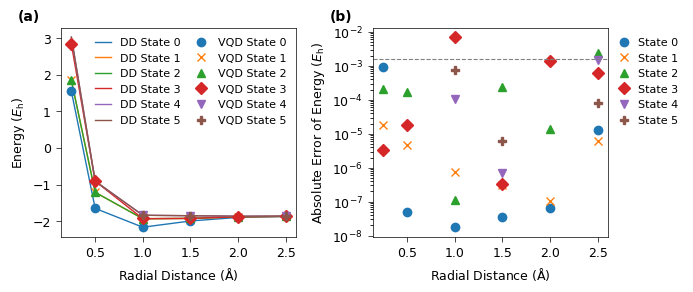

In [17]:


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.0))

# --- Panel (a): PES ---
for i in range(max_level):
    ax1.plot(distances, H_qumode_energies[:, i],
             label=f'DD State {i}', linestyle='-', color=colors[i])

for i in range(max_level):
    xs = [distances[j] for j, en in enumerate(vqd_values) if i < len(en)]
    ys = [en[i]        for en in vqd_values              if i < len(en)]
    ax1.plot(xs, ys, label=f'VQD State {i}', marker=markers[i],
             linestyle='', markersize=markersize, color=colors[i])

ax1.set_xlabel(r'Radial Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax1.set_ylabel(r'Energy ($E_\mathrm{h}$)', fontsize=fontsize)
ax1.tick_params(axis='both', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, ncol=2, frameon=False,
           handlelength=1.5, columnspacing=1.0)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Error ---
for i in range(max_level):
    xs = [distances[j] for j, en in enumerate(vqd_values) if i < len(en)]
    ys = [abs(en[i] - H_qumode_energies[j][i])
          for j, en in enumerate(vqd_values) if i < len(en)]
    ax2.plot(xs, ys, marker=markers[i], linestyle='',
             markersize=markersize, color=colors[i], label=f'State {i}')

ax2.axhline(y=1.6e-3, color='grey', linestyle='--', linewidth=0.8)
ax2.set_yscale('log')
ax2.set_xlabel(r'Radial Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax2.set_ylabel(r'Absolute Error of Energy ($E_\mathrm{h}$)', fontsize=fontsize)
ax2.tick_params(axis='both', labelsize=fontsize)
ax2.legend(fontsize=fontsize - 1, frameon=False, handlelength=1.0,
           loc='upper left', bbox_to_anchor=(1, 1),)
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig('Plots/Fig_H4_PES_and_Error.png', dpi=600, bbox_inches='tight')
plt.show()

# H4 Sliced

## VQD Energies

In [ ]:
distances = [0.25, 0.5, 1.0, 1.5, 2.0, 2.5]

# I removed values with high overlaps, degenergate, or abnormally high energies

en_pt25 = [
  1.5489087461139934,
  3.2120521626843495,
  3.507086527862005,
  4.363836224960918,
] 

en_pt5 = [
  -1.60498034786683,
  -0.908862483514986,
] 



en_1 = [
  -2.166387457696097,
  -1.9337573077001244,
  -1.7193482979209043,
] 

en_1pt5 = [
  -1.996150341582315,
  -1.9255586331244028,
  -1.8528938254956087,
  -1.813028952855257,
  -1.7736606370282022,
] 

en_2 = [
  -1.8977716730971932,
  -1.881880509777011,
  -1.8649404329310872,
  -1.8512345409751259,
  -1.8476901295803236
]

en_2pt5 = [  
  -1.867210881145183,
  -1.8692556872757615,
  -1.866136048628625,
  ] 

vqd_values = [en_pt25, en_pt5, en_1, en_1pt5, en_2, en_2pt5]

## FCI Energies

In [19]:
max_level = max([len(en) for en in vqd_values])
fci_values = np.array([compute_fci_states_h4(R, max_level) for R in distances])

## Plotting

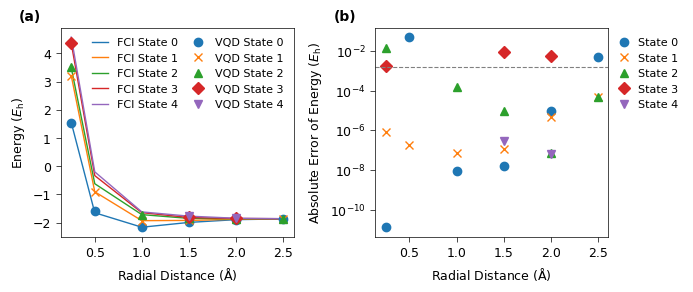

In [22]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3.0))

# --- Panel (a): PES ---
for i in range(max_level):
    ax1.plot(distances, fci_values[:, i],
             label=f'FCI State {i}', linestyle='-', color=colors[i])

for i in range(max_level):
    xs = [distances[j] for j, en in enumerate(vqd_values) if i < len(en)]
    ys = [en[i]        for en in vqd_values              if i < len(en)]
    ax1.plot(xs, ys, label=f'VQD State {i}', marker=markers[i],
             linestyle='', markersize=markersize, color=colors[i])

ax1.set_xlabel(r'Radial Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax1.set_ylabel(r'Energy ($E_\mathrm{h}$)', fontsize=fontsize)
ax1.tick_params(axis='both', labelsize=fontsize)
ax1.legend(fontsize=fontsize - 1, ncol=2, frameon=False,
           handlelength=1.5, columnspacing=1.0)
ax1.text(-0.18, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

# --- Panel (b): Error ---
for i in range(max_level):
    xs = [distances[j] for j, en in enumerate(vqd_values) if i < len(en)]
    ys = [abs(en[i] - fci_values[j][i])
          for j, en in enumerate(vqd_values) if i < len(en)]
    ax2.plot(xs, ys, marker=markers[i], linestyle='',
             markersize=markersize, color=colors[i], label=f'State {i}')

ax2.axhline(y=1.6e-3, color='grey', linestyle='--', linewidth=0.8)
ax2.set_yscale('log')
ax2.set_xlabel(r'Radial Distance ($\mathrm{\AA}$)', fontsize=fontsize)
ax2.set_ylabel(r'Absolute Error of Energy ($E_\mathrm{h}$)', fontsize=fontsize)
ax2.tick_params(axis='both', labelsize=fontsize)
ax2.legend(fontsize=fontsize - 1, frameon=False, handlelength=1.0,
           loc='upper left', bbox_to_anchor=(1, 1),)
ax2.text(-0.18, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=fontsize + 1, fontweight='bold', va='bottom', ha='left')

fig.tight_layout()
fig.savefig('Plots/Fig_H4_Sliced_PES_and_Error.png', dpi=600, bbox_inches='tight')
plt.show()